# 02 — Graph Construction and Visualization
Build the **road-segment graph** where each directed road segment is a node, and graph edges encode valid segment-to-segment transitions.


## Representation notes
- Intersection graph: intersections as nodes, roads as edges.
- Segment graph (used here): directed road segments as nodes.
- SUMO uses edge/lane entities; mapping is explicit and stable.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
RAW = PROJECT_ROOT / "data" / "raw" / "road_edges_fallback.csv"
PROC = PROJECT_ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

roads = pd.read_csv(RAW)
roads["road_segment_id"] = [f"seg_{i:04d}" for i in range(len(roads))]
roads.head()


,u,v,length_m,speed_kmh,oneway,source,road_segment_id
0,0,1,167,52,1,deterministic_fallback,seg_0000
1,1,0,167,52,0,deterministic_fallback,seg_0001
2,1,2,349,55,1,deterministic_fallback,seg_0002
3,2,1,349,55,0,deterministic_fallback,seg_0003
4,2,3,226,28,1,deterministic_fallback,seg_0004


In [2]:
# Map each directed road segment to graph node index
segment_to_node = {sid:i for i, sid in enumerate(roads["road_segment_id"]) }

# valid transition: end-node of segment A == start-node of segment B
transition_edges = []
by_start = {}
for idx, row in roads.iterrows():
    by_start.setdefault(int(row["u"]), []).append(row["road_segment_id"])

for _, r1 in roads.iterrows():
    end_intersection = int(r1["v"])
    next_segments = by_start.get(end_intersection, [])
    for sid2 in next_segments:
        sid1 = r1["road_segment_id"]
        transition_edges.append((segment_to_node[sid1], segment_to_node[sid2]))

transition_edges = sorted(set(transition_edges))
print("Segment nodes:", len(segment_to_node), "Transition edges:", len(transition_edges))


Segment nodes: 313 Transition edges: 565


Weak components: 2
Isolated nodes: 0


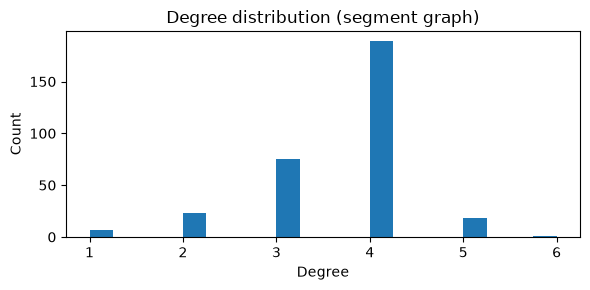

In [3]:
Gseg = nx.DiGraph()
Gseg.add_nodes_from(range(len(segment_to_node)))
Gseg.add_edges_from(transition_edges)

print("Weak components:", nx.number_weakly_connected_components(Gseg))
print("Isolated nodes:", sum(1 for n in Gseg.nodes if Gseg.degree(n)==0))

deg = [Gseg.degree(n) for n in Gseg.nodes]
plt.figure(figsize=(6,3))
plt.hist(deg, bins=20)
plt.title("Degree distribution (segment graph)")
plt.xlabel("Degree")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


In [4]:
mapping_df = roads[["road_segment_id", "u", "v", "length_m", "speed_kmh"]].copy()
mapping_df["graph_node_id"] = mapping_df["road_segment_id"].map(segment_to_node)

edge_df = pd.DataFrame(transition_edges, columns=["src", "dst"])

mapping_df.to_csv(PROC / "road_segment_mapping.csv", index=False)
edge_df.to_csv(PROC / "segment_graph_edges.csv", index=False)
print("Saved mapping and edge_index tables to data/processed")


Saved mapping and edge_index tables to data/processed


## Validation
Transitions preserve directionality and network connectivity; roads are connected by legal topological continuation, not Euclidean closeness.
